# GCSI Headline Feed Live Polling

## Integration guide: Global Commodity Sentiment Indices, headline feed

The headline feed is the input to the hourly index: one row per headline × commodity × topic, each with a
**match type** and **three horizon scores**. Use it when you want your own aggregation windows, your own
filters, or the headlines behind a move. The same pattern, as three Docker services, is in
`app/live_headline_polling/`.

### Output schema

| Field | Description |
|---|---|
| `headline`, `link`, `source_name` | The article (publisher content: use it under your licence, do not republish) |
| `ticker` | The commodity |
| `match_type` | `EXPLICIT`, `RELATED_ENTITY` or `MACROECONOMIC` |
| `matched_entity_types`, `matched_entities` | What linked the headline to the commodity, e.g. `PHYSICAL_ASSET.PROCESSING_FACILITY` and `Ras Tanura Refinery`. Pipe-separated lists. |
| `country` | Countries the headline is about, pipe-separated |
| `source_country`, `language` | Where the publisher is based, and the language of the headline |
| `topic` | Topic label, `Sector::L1::L2` |
| `topic_probability` | Classifier confidence (0–1) that the headline belongs to the topic. This is not sentiment. |
| `short_term_sentiment_score` / `medium_term_…` / `long_term_…` | Horizon scores from −1 to +1, positive = bullish for price |
| `processed_at` | When Permutable processed it and made it available (UTC). The hourly index is binned on this field. |

### What this notebook shows

1. Polling the feed into SQLite without duplicates
2. The match-type mix, and why `topic_probability` is a filter rather than a score
3. Who and where: the entities, countries and sources behind the news
4. Building your own 15-minute index, binned on **processed time** so it matches the published hourly index

> **Disclaimer:** This notebook is provided for informational and research purposes only. Nothing here constitutes financial advice or a recommendation to buy, sell, or hold any asset. Sentiment scores are model outputs describing how news was judged at publication; they are not price forecasts.

In [ ]:
%pip install requests pandas numpy matplotlib seaborn

## Step 1: Configuration

The API client, storage, metrics and chart helpers live in [`../utils`](../utils/), shared by every notebook in this folder. Open them to see how each step works.

In [2]:
import os
import sys
import time
from datetime import datetime, timedelta, timezone
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path('..').resolve()))  # notebooks/, for the shared utils package
from utils import charts, metrics
from utils.api import GcsiClient
from utils.store import FeedStore

TICKERS = ['BZ_COM']
MATCH_TYPES = [None]               # None uses the API default COMBINED; or e.g. ['EXPLICIT', 'RELATED_ENTITY']
BACKFILL_HOURS = 48
POLL_INTERVAL_SECONDS = 900
MIN_TOPIC_PROBABILITY = 0.0        # raise to keep only confident topic assignments
AGG_FREQ = '15min'
DB_PATH = 'gcsi_headlines_nb.db'

# Publisher text is shown when you run the notebook. The saved outputs in this repository were run with
# SHOW_HEADLINE_TEXT=0, so their tables leave out the headline, link and publisher.
SHOW_HEADLINE_TEXT = os.environ.get('SHOW_HEADLINE_TEXT', '1') == '1'
PUBLISHER_COLUMNS = ['headline', 'link', 'source_name']

client = GcsiClient()              # API_KEY from the environment or a .env file, otherwise a prompt
store = FeedStore(DB_PATH)         # keyed on ticker, topic, match type, time and link, so re-polling is harmless
TICKER_NAME = charts.ticker_label(TICKERS[0])

## Step 2: Dry run and backfill

The feed has no row id, so `FeedStore` keys each row on (ticker, topic, match type, processed time, link or headline). Polling the same window twice is then harmless.

In [3]:
sample = client.feed_live(TICKERS[0])
print(f'{len(sample)} live rows for {TICKERS[0]}; fields: {sorted(sample[0]) if sample else "none"}')

start = datetime.now(timezone.utc) - timedelta(hours=BACKFILL_HOURS)
for ticker in TICKERS:
    for match_type in MATCH_TYPES:
        n = store.upsert(client.feed_history(ticker, start, match_type=match_type))
        print(f'{ticker} / {match_type or "all match types"}: {n:,} rows upserted')

feed = store.load(hours=BACKFILL_HOURS)
feed = feed[feed['topic_probability'] >= MIN_TOPIC_PROBABILITY]
print(f'{len(feed):,} rows | {feed["link"].nunique():,} distinct links | {feed["topic"].nunique()} topics')

1000 live rows for BZ_COM; fields: ['country', 'headline', 'language', 'link', 'long_term_sentiment_score', 'match_type', 'matched_entities', 'matched_entity_types', 'medium_term_sentiment_score', 'processed_at', 'short_term_sentiment_score', 'source_country', 'source_name', 'ticker', 'topic', 'topic_probability']


BZ_COM / all match types: 31,451 rows upserted


30,276 rows | 24,973 distinct links | 21 topics


## Step 3: Match types and topic probability

One headline can appear several times for a ticker: once per topic. Within a ticker, each headline has a single
match type (priority `EXPLICIT`, then `RELATED_ENTITY`, then `MACROECONOMIC`).
`topic_probability` measures how sure the classifier is about the *topic*. A low value does not mean low
sentiment, so use it to trade coverage for precision.

,rows,links,avg_short_term
match_type,,,
EXPLICIT,12966,9416,-0.242
MACROECONOMIC,16101,14536,0.008
RELATED_ENTITY,1209,1021,-0.030


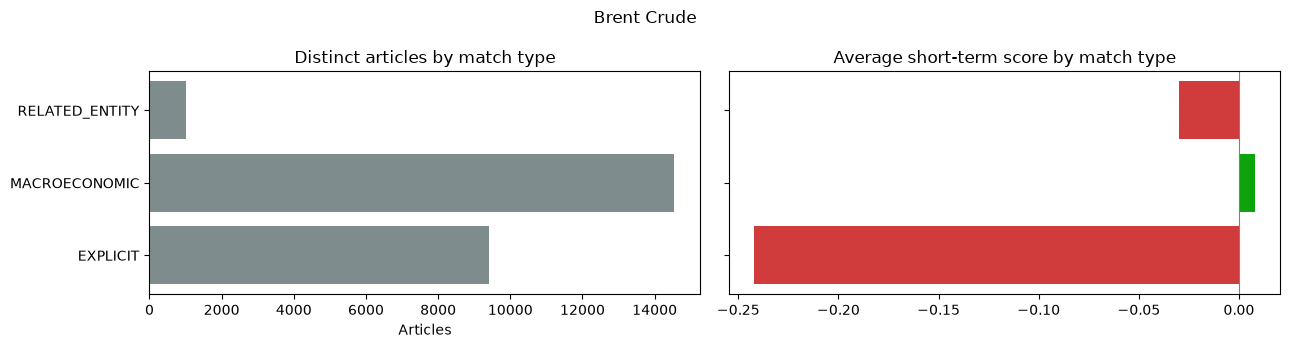

In [4]:
mix = feed.groupby('match_type').agg(rows=('row_key', 'size'), links=('link', 'nunique'),
                                      avg_short_term=('short_term_sentiment_score', 'mean')).round(3)
display(mix)
charts.match_mix(mix, TICKER_NAME)

## Step 4: Who and where: entities, countries and coverage

Each headline also records **what** linked it to the commodity (`matched_entity_types`, `matched_entities`),
**which countries** it is about (`country`) and **where it came from** (`source_country`, `language`).
The first three are `|`-separated lists, so split them and count each article once per value.

Counts are distinct articles. The feed repeats an article once per topic, so each article's short-term score is
averaged across its topics before it is averaged by entity or country.

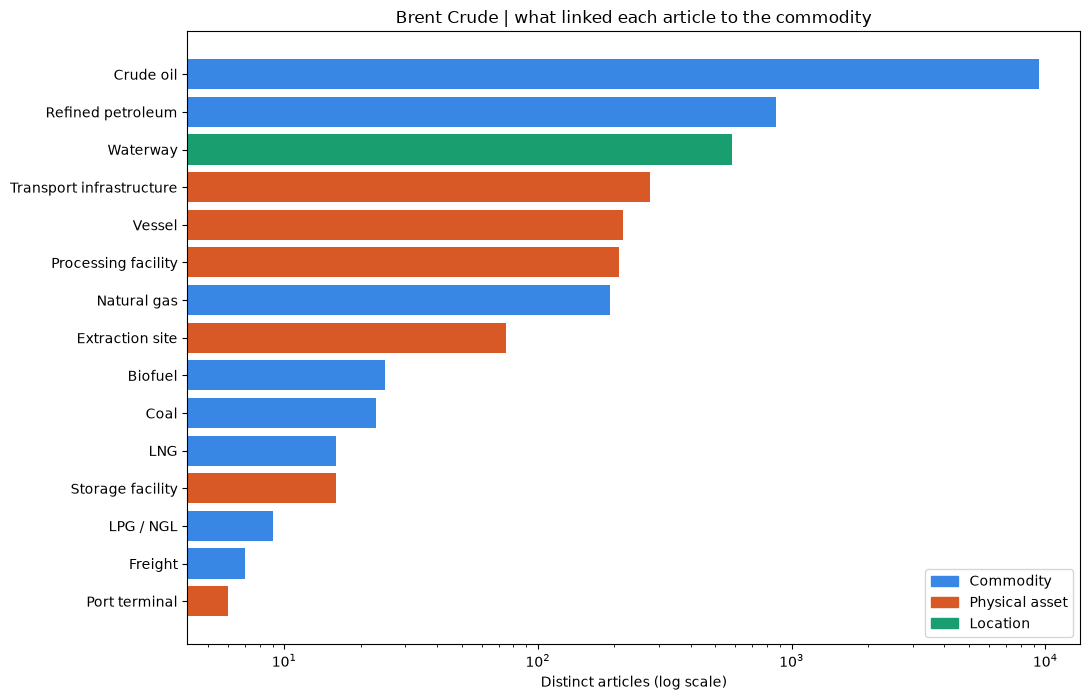

In [5]:
news = metrics.articles(feed)  # one row per article
types = metrics.by_value(news, 'matched_entity_types', n=15)
charts.entity_types(types, f'{TICKER_NAME} | what linked each article to the commodity')

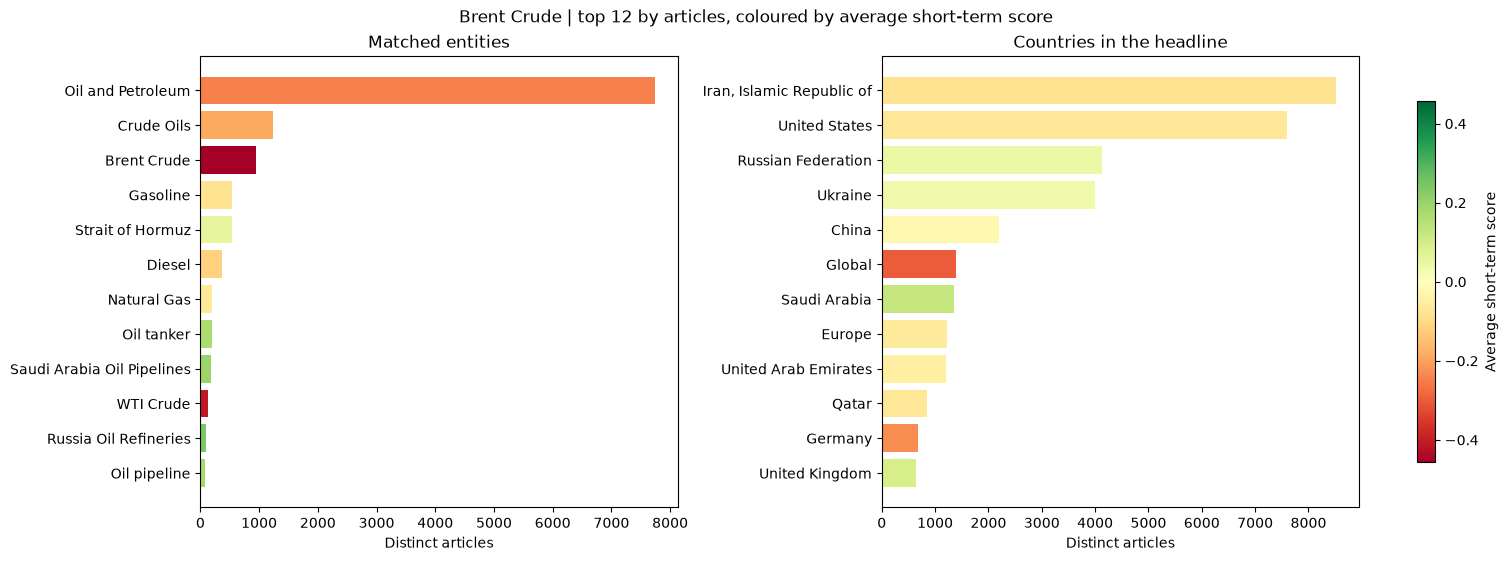

In [6]:
panels = {'Matched entities': metrics.by_value(news, 'matched_entities'),
          'Countries in the headline': metrics.by_value(news, 'country')}
charts.ranked_by_score(panels, f'{TICKER_NAME} | top 12 by articles, coloured by average short-term score')

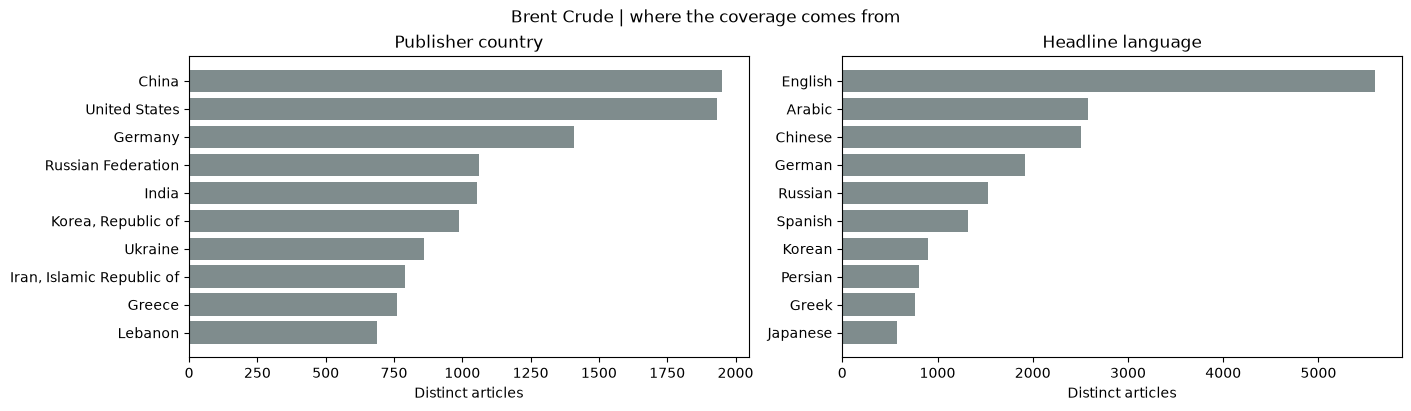

In [7]:
charts.coverage(news, f'{TICKER_NAME} | where the coverage comes from')

## Step 5: Your own index on processed time

Bin on `processed_at` (when Permutable processed the headline and made it available), labelling each bin by its **end**, as the
hourly index does. The feed does not carry a publisher publication time.

One article can appear in several topics, so the `headline_count` here counts topic-links.

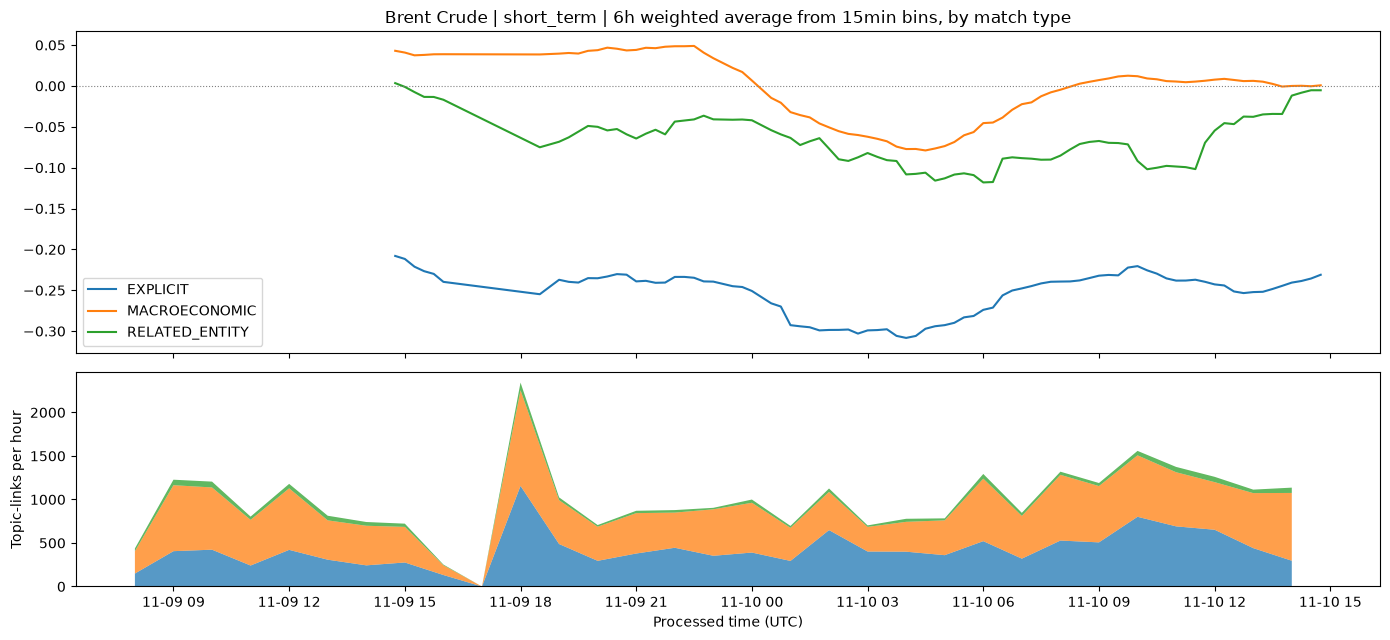

In [8]:
own = metrics.own_index(feed, freq=AGG_FREQ)
charts.own_index_by_match_type(own, f'{TICKER_NAME} | short_term | 6h weighted average from {AGG_FREQ} bins, '
                                    'by match type')

## Step 6: Topic heatmap

The busiest topics in the window, with cells under five topic-links left blank.

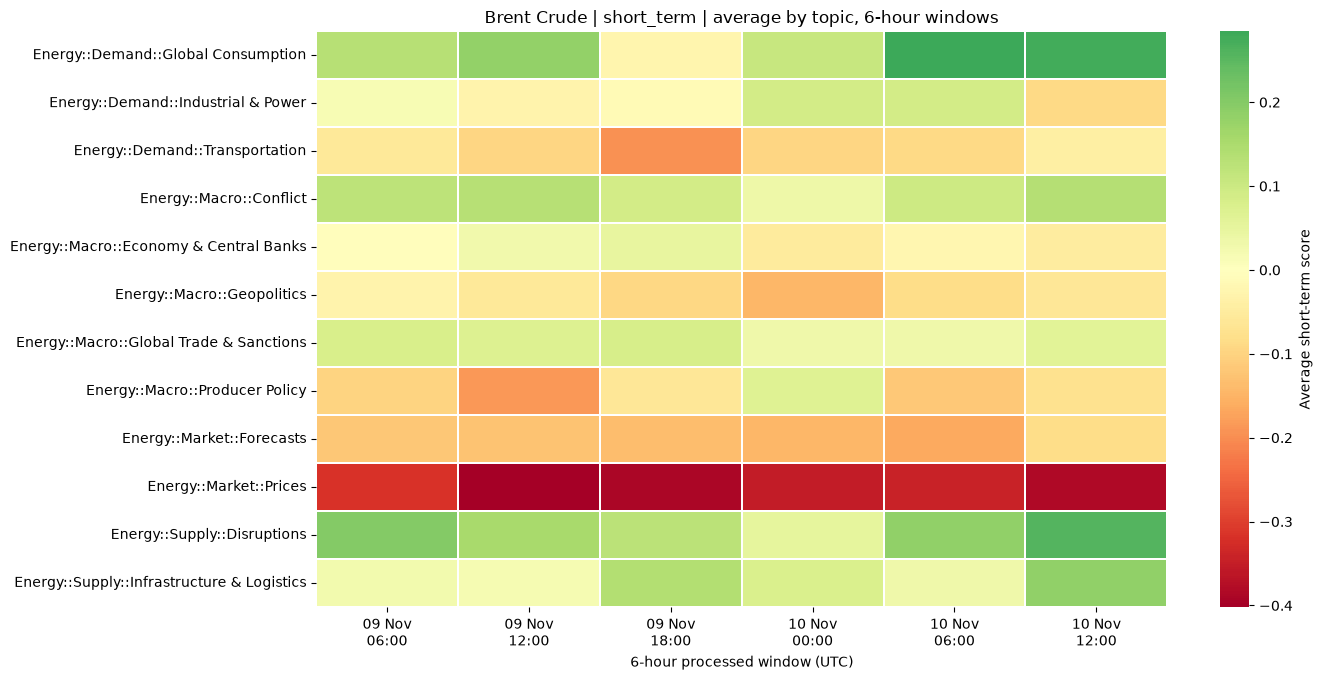

In [9]:
grid = metrics.windowed_topic_average(feed, freq='6h', min_headlines=5, top=12)
charts.topic_heatmap(grid, f'{TICKER_NAME} | short_term | average by topic, 6-hour windows',
                     xlabel='6-hour processed window (UTC)', colourbar='Average short-term score')

## Step 7: Strongest headlines

The headlines behind the most recent move, ranked by absolute short-term score. These are for your own analysis.
Publisher text should not be republished: set `SHOW_HEADLINE_TEXT` to see it, as the saved outputs here do not.

In [10]:
recent = feed[feed['processed_at'] >= feed['processed_at'].max() - pd.Timedelta(hours=6)]
strongest = recent.reindex(recent['short_term_sentiment_score'].abs().sort_values(ascending=False).index)
columns = ['processed_at', 'match_type', 'topic', 'short_term_sentiment_score', 'country', 'matched_entities',
           'headline', 'source_name']
if not SHOW_HEADLINE_TEXT:
    columns = [c for c in columns if c not in PUBLISHER_COLUMNS]
display(strongest.drop_duplicates('link')[columns].head(10))

,processed_at,match_type,topic,short_term_sentiment_score,country,matched_entities
25698,2026-11-10 11:08:35.398961+00:00,EXPLICIT,Energy::Market::Prices,-0.995,Sri Lanka,Brent Crude
24222,2026-11-10 10:02:25.273803+00:00,EXPLICIT,Energy::Market::Prices,-0.991,"Iran, Islamic Republic of",Brent Crude|Crude Oils
27929,2026-11-10 12:36:11.863492+00:00,EXPLICIT,Energy::Market::Prices,-0.989,China|Saudi Arabia,Oil and Petroleum
25132,2026-11-10 10:38:15.113144+00:00,EXPLICIT,Energy::Market::Prices,-0.985,"Iran, Islamic Republic of|Saudi Arabia",Brent Crude|Crude Oils|Oil and Petroleum
23145,2026-11-10 09:15:37.295891+00:00,EXPLICIT,Energy::Market::Prices,-0.984,"Iran, Islamic Republic of|Saudi Arabia",Brent Crude|Crude Oils|Oil and Petroleum
27003,2026-11-10 11:57:57.552598+00:00,EXPLICIT,Energy::Market::Prices,-0.982,Saudi Arabia,Brent Crude|Oil and Petroleum
26263,2026-11-10 11:33:08.516913+00:00,EXPLICIT,Energy::Market::Prices,-0.982,Global,Oil and Petroleum
27860,2026-11-10 12:36:11.863492+00:00,EXPLICIT,Energy::Market::Prices,-0.978,Brazil,Brent Crude
25147,2026-11-10 10:38:15.113144+00:00,MACROECONOMIC,Energy::Market::Prices,-0.968,"Iran, Islamic Republic of",NaN
25173,2026-11-10 10:38:15.113144+00:00,MACROECONOMIC,Energy::Market::Prices,-0.968,"Iran, Islamic Republic of",NaN


## Step 8: Live polling loop

In [11]:
RUN_POLLING_LOOP = False

if RUN_POLLING_LOOP:
    while True:
        started = datetime.now(timezone.utc)
        n = sum(store.upsert(client.feed_live(t, m)) for t in TICKERS for m in MATCH_TYPES)
        print(f'{started:%H:%M:%S} UTC: {n} rows upserted')
        time.sleep(max(0, POLL_INTERVAL_SECONDS - (datetime.now(timezone.utc) - started).total_seconds()))
else:
    print('Polling loop disabled: set RUN_POLLING_LOOP = True to start it.')

Polling loop disabled: set RUN_POLLING_LOOP = True to start it.
